# Module 4 Demo — End-to-End Training & Testing Pipeline

In Module 3 we built a `ColumnTransformer`. Now we snap it directly into a **`sklearn.pipeline.Pipeline`** together with our classifier so that:
- Cross-validation **automatically refits preprocessing inside every fold** (zero data leakage!).
- We save **ONE file (`churn_pipeline.joblib`)** that contains feature creation + imputation + scaling + encoding + the trained model!
- At inference time, we pass a raw customer dictionary/DataFrame and immediately get a churn probability.

### What You Will Learn in This Demo
1. Wrapping custom feature engineering (`FunctionTransformer`) + `ColumnTransformer` + Classifier into one unified `Pipeline`.
2. Comparing 3 candidate models using **5-fold Stratified Cross-Validation** (`ROC-AUC` and `F1`).
3. Final untouched **Test Set Evaluation** (Classification Report, Confusion Matrix, ROC Curve).
4. **Artifact Serialization & Inference Smoke Test**: Saving the pipeline with `joblib`, writing a model metadata JSON, reloading from disk, and scoring a brand-new customer!


In [1]:
import json
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler


def load_streampulse_dataset() -> pd.DataFrame:
    cust = pd.read_csv("data/customers_raw.csv")
    with open("data/usage_events.json", "r", encoding="utf-8") as f:
        usage = pd.DataFrame(json.load(f))
    cust["plan_tier"] = cust["plan_tier"].apply(lambda x: x.strip().lower() if isinstance(x, str) else x)
    cust["country"] = cust["country"].apply(lambda x: x.strip().upper() if isinstance(x, str) else x)
    cust = cust.drop_duplicates(subset=["customer_id"], keep="first")
    return cust.merge(usage, on="customer_id", how="left")


df = load_streampulse_dataset()
RAW_FEATURE_COLS = [
    "age", "tenure_months", "monthly_charges",
    "login_days_30d", "watch_hours_30d", "support_tickets_30d",
    "auto_pay", "plan_tier", "country", "payment_method", "last_active_device",
]
X = df[RAW_FEATURE_COLS]
y = df["churned"]

# Stratified split keeps the same churn ratio in both train and test sets!
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train size: {len(X_train)} (churn rate: {y_train.mean():.1%})")
print(f"Test size : {len(X_test)} (churn rate: {y_test.mean():.1%})")


Train size: 800 (churn rate: 29.5%)
Test size : 200 (churn rate: 29.5%)


## Part 1: Building a Single End-to-End Pipeline Factory

Notice how `FunctionTransformer(add_domain_features)` sits as Step 1 of our `Pipeline`. That means even raw inputs at prediction time automatically receive the exact same derived features!


In [2]:
def add_domain_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out["charges_per_login"] = out["monthly_charges"] / (out["login_days_30d"] + 1.0)
    out["tickets_per_tenure_month"] = out["support_tickets_30d"] / (out["tenure_months"] + 1.0)
    out["watch_hours_per_login"] = out["watch_hours_30d"] / (out["login_days_30d"] + 1.0)
    out["is_new_customer"] = (out["tenure_months"] <= 3).astype(int)
    return out


NUMERIC_FEATURES = [
    "age", "tenure_months", "monthly_charges",
    "login_days_30d", "watch_hours_30d", "support_tickets_30d",
    "auto_pay", "charges_per_login", "tickets_per_tenure_month",
    "watch_hours_per_login", "is_new_customer",
]
CATEGORICAL_FEATURES = ["plan_tier", "country", "payment_method", "last_active_device"]


def build_full_pipeline(model) -> Pipeline:
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]),
                NUMERIC_FEATURES,
            ),
            (
                "cat",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                    ]
                ),
                CATEGORICAL_FEATURES,
            ),
        ]
    )
    return Pipeline(
        steps=[
            ("domain_features", FunctionTransformer(add_domain_features, validate=False)),
            ("preprocessor", preprocessor),
            ("classifier", model),
        ]
    )


## Part 2: Comparing Candidate Models via 5-Fold Stratified Cross-Validation

Never pick your model by looking at the test set! Instead, compare candidates using **Cross-Validation on `X_train` only**.


In [3]:
candidates = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "RandomForest": RandomForestClassifier(
        n_estimators=150, max_depth=6, min_samples_leaf=4, class_weight="balanced", random_state=42
    ),
    "GradientBoosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for name, estimator in candidates.items():
    pipe = build_full_pipeline(estimator)
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "f1", "accuracy"], n_jobs=1
    )
    rows.append(
        {
            "model": name,
            "cv_roc_auc_mean": round(float(scores["test_roc_auc"].mean()), 4),
            "cv_roc_auc_std": round(float(scores["test_roc_auc"].std()), 4),
            "cv_f1_mean": round(float(scores["test_f1"].mean()), 4),
            "cv_accuracy_mean": round(float(scores["test_accuracy"].mean()), 4),
        }
    )

cv_results = pd.DataFrame(rows).sort_values("cv_roc_auc_mean", ascending=False).reset_index(drop=True)
print("5-Fold Cross-Validation Leaderboard (Training Set Only):")
cv_results


5-Fold Cross-Validation Leaderboard (Training Set Only):


,model,cv_roc_auc_mean,cv_roc_auc_std,cv_f1_mean,cv_accuracy_mean
0,LogisticRegression,0.8207,0.0323,0.6169,0.7400
1,RandomForest,0.8199,0.0320,0.6196,0.7750
2,GradientBoosting,0.8129,0.0418,0.6295,0.8088


## Part 3: Final Evaluation on the Untouched Test Set

Now we select the top CV performer, refit it on the full `X_train`, and evaluate **once** on `X_test`.


=== Held-Out Test Set Metrics (LogisticRegression) ===
{
  "selected_model": "LogisticRegression",
  "accuracy": 0.72,
  "precision": 0.519,
  "recall": 0.6949,
  "f1": 0.5942,
  "roc_auc": 0.8134
}

Classification Report:
              precision    recall  f1-score   support

Retained (0)       0.85      0.73      0.79       141
 Churned (1)       0.52      0.69      0.59        59

    accuracy                           0.72       200
   macro avg       0.69      0.71      0.69       200
weighted avg       0.75      0.72      0.73       200



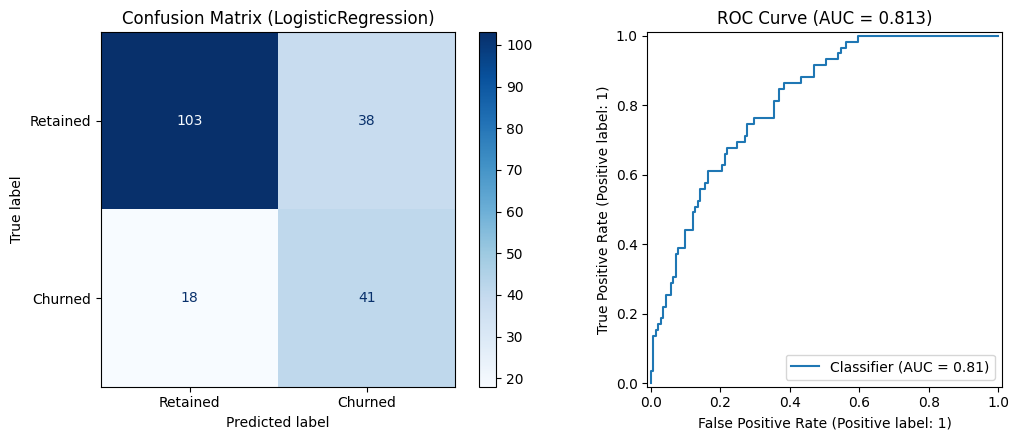

In [4]:
best_model_name = cv_results.loc[0, "model"]
best_pipeline = build_full_pipeline(candidates[best_model_name])
best_pipeline.fit(X_train, y_train)

y_pred = best_pipeline.predict(X_test)
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

test_metrics = {
    "selected_model": best_model_name,
    "accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
    "precision": round(float(precision_score(y_test, y_pred)), 4),
    "recall": round(float(recall_score(y_test, y_pred)), 4),
    "f1": round(float(f1_score(y_test, y_pred)), 4),
    "roc_auc": round(float(roc_auc_score(y_test, y_prob)), 4),
}

print(f"=== Held-Out Test Set Metrics ({best_model_name}) ===")
print(json.dumps(test_metrics, indent=2))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Retained (0)", "Churned (1)"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Retained", "Churned"], cmap="Blues", ax=axes[0]
)
axes[0].set_title(f"Confusion Matrix ({best_model_name})")

RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].set_title(f"ROC Curve (AUC = {test_metrics['roc_auc']:.3f})")
plt.tight_layout()
plt.show()


## Part 4: Saving the Pipeline Artifact & Running an Inference Smoke Test

A model that only lives in RAM disappears when Jupyter restarts. Let's save:
1. `artifacts/demo_churn_pipeline.joblib` — the complete end-to-end pipeline.
2. `artifacts/demo_churn_metadata.json` — model name, required raw features, and test metrics.

Then we reload the `.joblib` from disk and test it on a realistic brand-new customer!


In [5]:
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

model_path = artifacts_dir / "demo_churn_pipeline.joblib"
meta_path = artifacts_dir / "demo_churn_metadata.json"

joblib.dump(best_pipeline, model_path)
meta_path.write_text(
    json.dumps(
        {
            "model_name": best_model_name,
            "required_raw_columns": RAW_FEATURE_COLS,
            "test_metrics": test_metrics,
        },
        indent=2,
    ),
    encoding="utf-8",
)
print(f"Saved model artifact : {model_path} ({model_path.stat().st_size:,} bytes)")
print(f"Saved model metadata : {meta_path}")

# Reload from disk (simulating a fresh production service!)
loaded_pipeline = joblib.load(model_path)

new_customers = pd.DataFrame(
    [
        {
            "age": 24, "tenure_months": 2, "monthly_charges": 24.99,
            "login_days_30d": 2, "watch_hours_30d": 1.5, "support_tickets_30d": 4,
            "auto_pay": 0, "plan_tier": "premium", "country": "US",
            "payment_method": "credit_card", "last_active_device": "mobile",
        },
        {
            "age": 38, "tenure_months": 36, "monthly_charges": 15.99,
            "login_days_30d": 26, "watch_hours_30d": 42.0, "support_tickets_30d": 0,
            "auto_pay": 1, "plan_tier": "standard", "country": "IN",
            "payment_method": "upi", "last_active_device": "smart_tv",
        },
    ]
)

probs = loaded_pipeline.predict_proba(new_customers)[:, 1]
preds = loaded_pipeline.predict(new_customers)
for idx, (pred, prob) in enumerate(zip(preds, probs), start=1):
    label = "HIGH RISK (Churn)" if pred == 1 else "LOW RISK (Retained)"
    print(f"  Customer #{idx}: prediction={label:<22} | churn_probability={prob:.1%}")


Saved model artifact : artifacts/demo_churn_pipeline.joblib (7,322 bytes)
Saved model metadata : artifacts/demo_churn_metadata.json
  Customer #1: prediction=HIGH RISK (Churn)      | churn_probability=100.0%
  Customer #2: prediction=LOW RISK (Retained)    | churn_probability=3.0%
